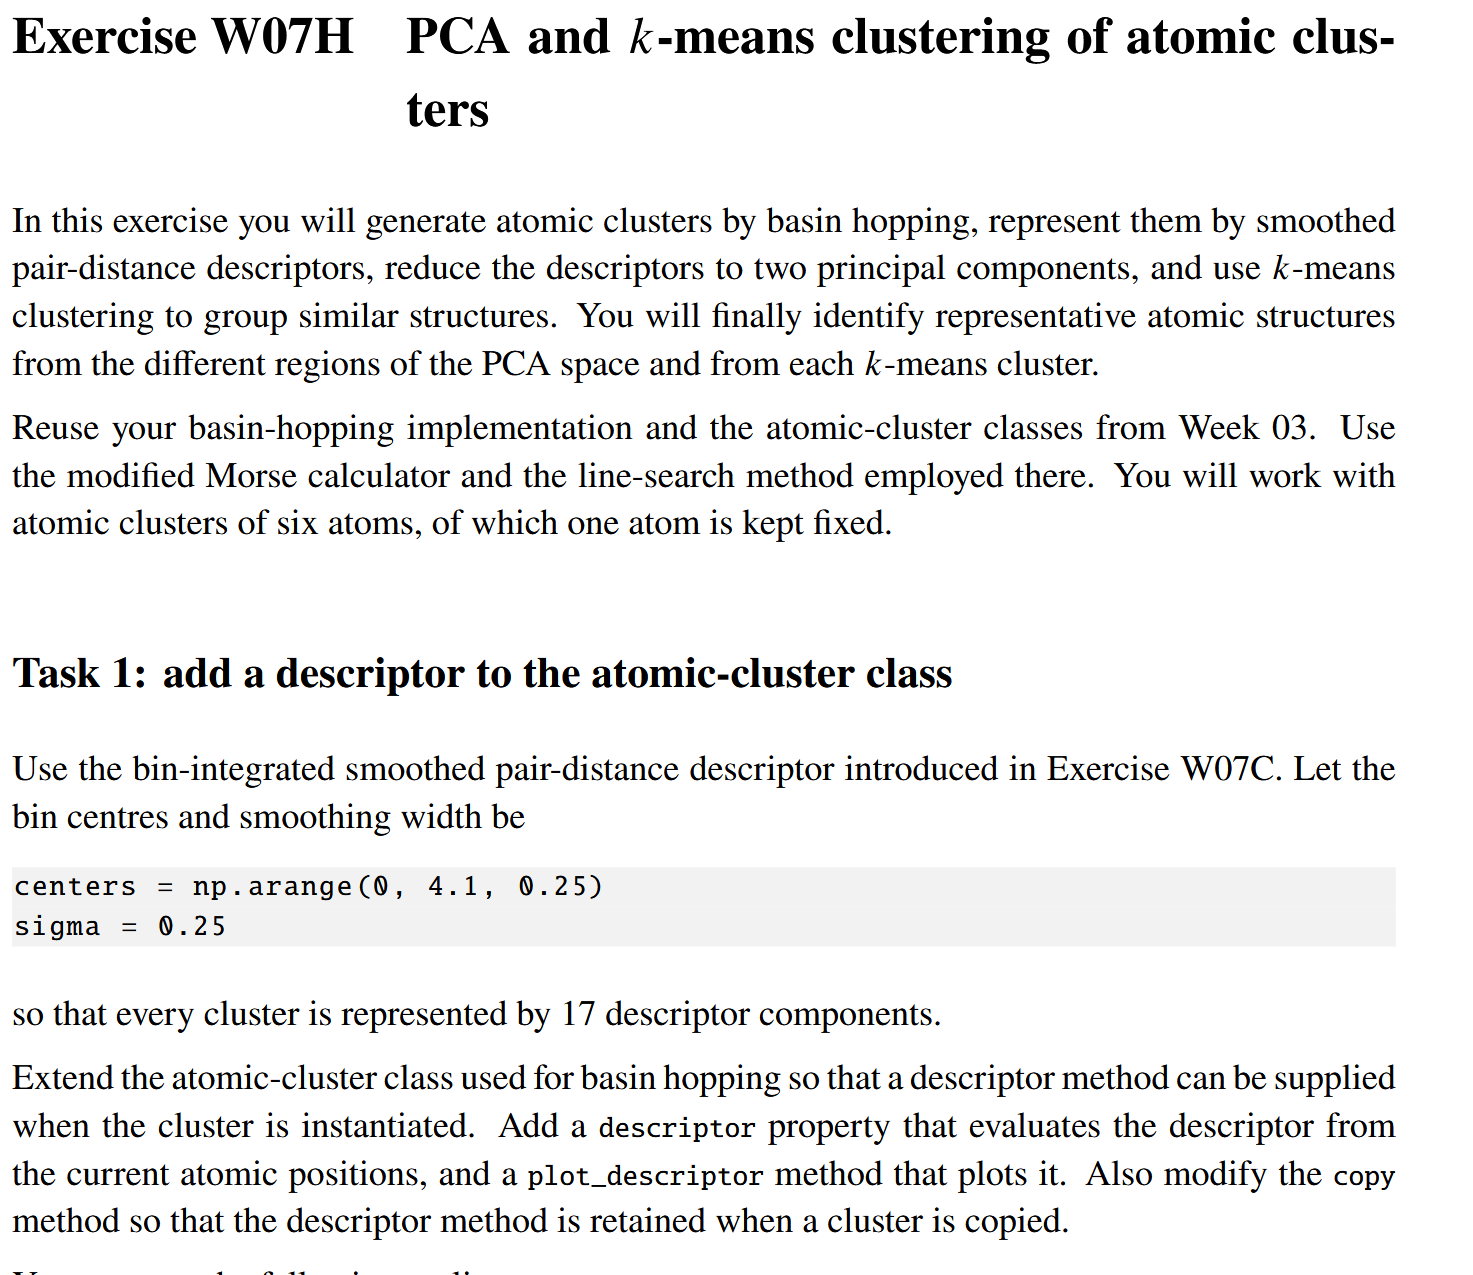

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from Pairdistance import *
from week03 import *

class ErfDescriptor(ErfDescriptor):
    def __init__(self, *args, sigma=0.25, dx=0.1, **kwargs):
        super().__init__(*args, sigma=sigma, dx=dx, **kwargs)
    
    centers = np.arange(0, 4.1, 0.25)
    ylim = [0, 1.5]

class AtomicCluster(AtomicClusterBase2):
    def __init__(self, *args, descriptor_method, **kwargs):
        super().__init__(*args, **kwargs)
        self.descriptor_method = descriptor_method

    def rattle_random_dynamic_atom(self, A=0.01):
            index = np.random.choice(self.indices_dynamic_atoms)
            self.pos[index] += np.random.normal(scale=A, size=2)

    @property
    def descriptor(self):
        return np.array(self.descriptor_method(self.pos))

    def plot_descriptor(self, ax, add_title=True):
        self.descriptor_method.plot(ax, self.pos, add_title)

    def copy(self):
        return self.__class__(self.calc, pos=self.pos, static=self.static, 
                              init_delta=self.init_delta, 
                              descriptor_method=self.descriptor_method)

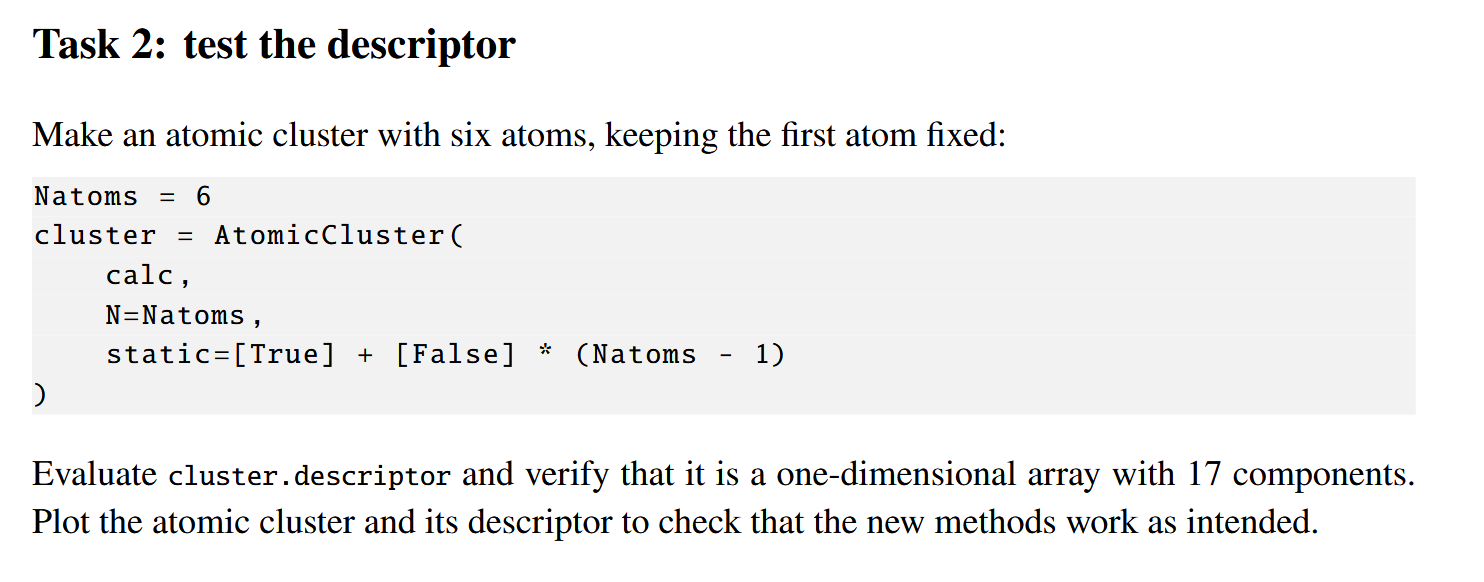

There are 17 components,they are: 
[1.01161020e-04 3.46858892e-03 4.64147631e-02 2.49867013e-01
 5.69531221e-01 6.35237529e-01 5.54851804e-01 5.61994049e-01
 5.73661854e-01 5.77319577e-01 5.11955790e-01 4.10729782e-01
 3.09738506e-01 2.75675511e-01 2.13576721e-01 1.13840389e-01
 1.16944115e-01]


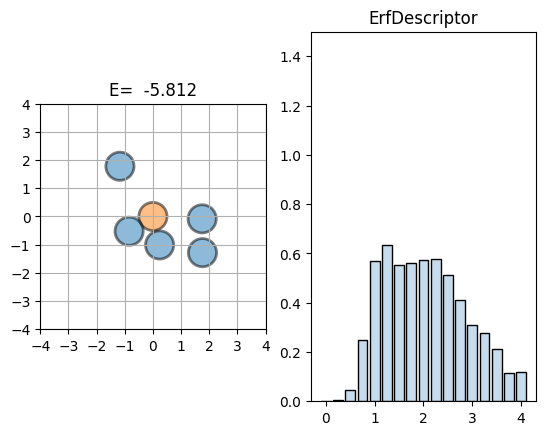

In [4]:
Natoms = 6 
calc = ModifiedMorseForce()
cluster = AtomicCluster(
    calc, Natoms, 
    static=[True] + [False] * (Natoms - 1),
    descriptor_method=ErfDescriptor()
)
cluster.pos[0] = [0,0]

desk = cluster.descriptor
print(f'There are {len(desk)} components,they are: \n{desk}')


fig, ax = plt.subplots(1, 2)
nice_plot(ax[0])
cluster.draw(ax[0])
cluster.plot_descriptor(ax[1])

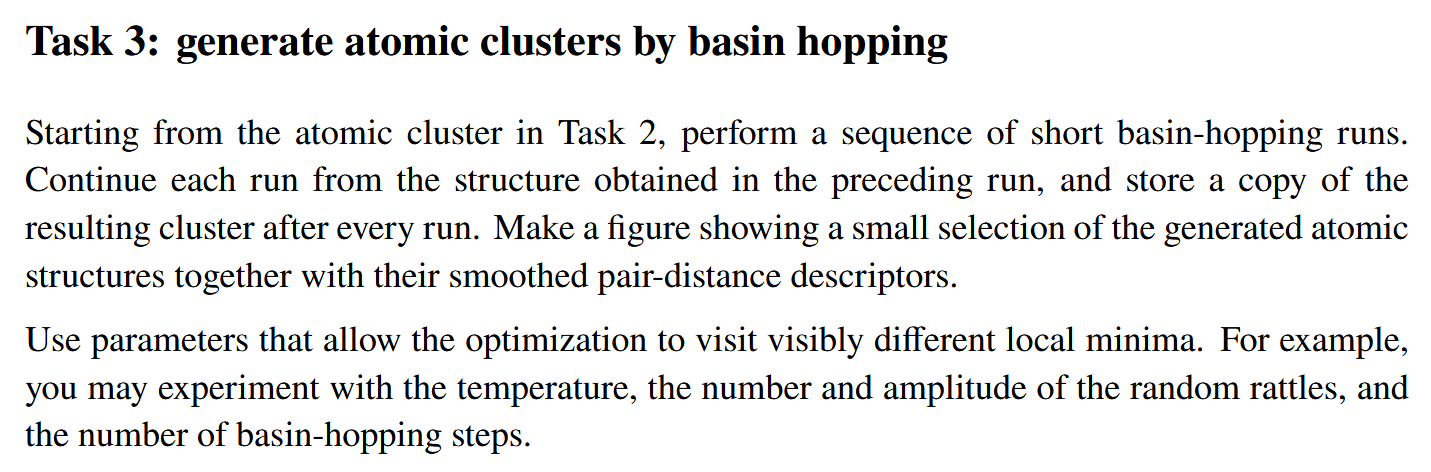

Run 1: Acceptance = 0.73 | Energy = -14.378
Run 2: Acceptance = 0.73 | Energy = -14.578
Run 3: Acceptance = 0.40 | Energy = -15.461
Run 4: Acceptance = 0.67 | Energy = -15.539
Run 5: Acceptance = 0.67 | Energy = -15.273
Run 6: Acceptance = 0.73 | Energy = -14.034


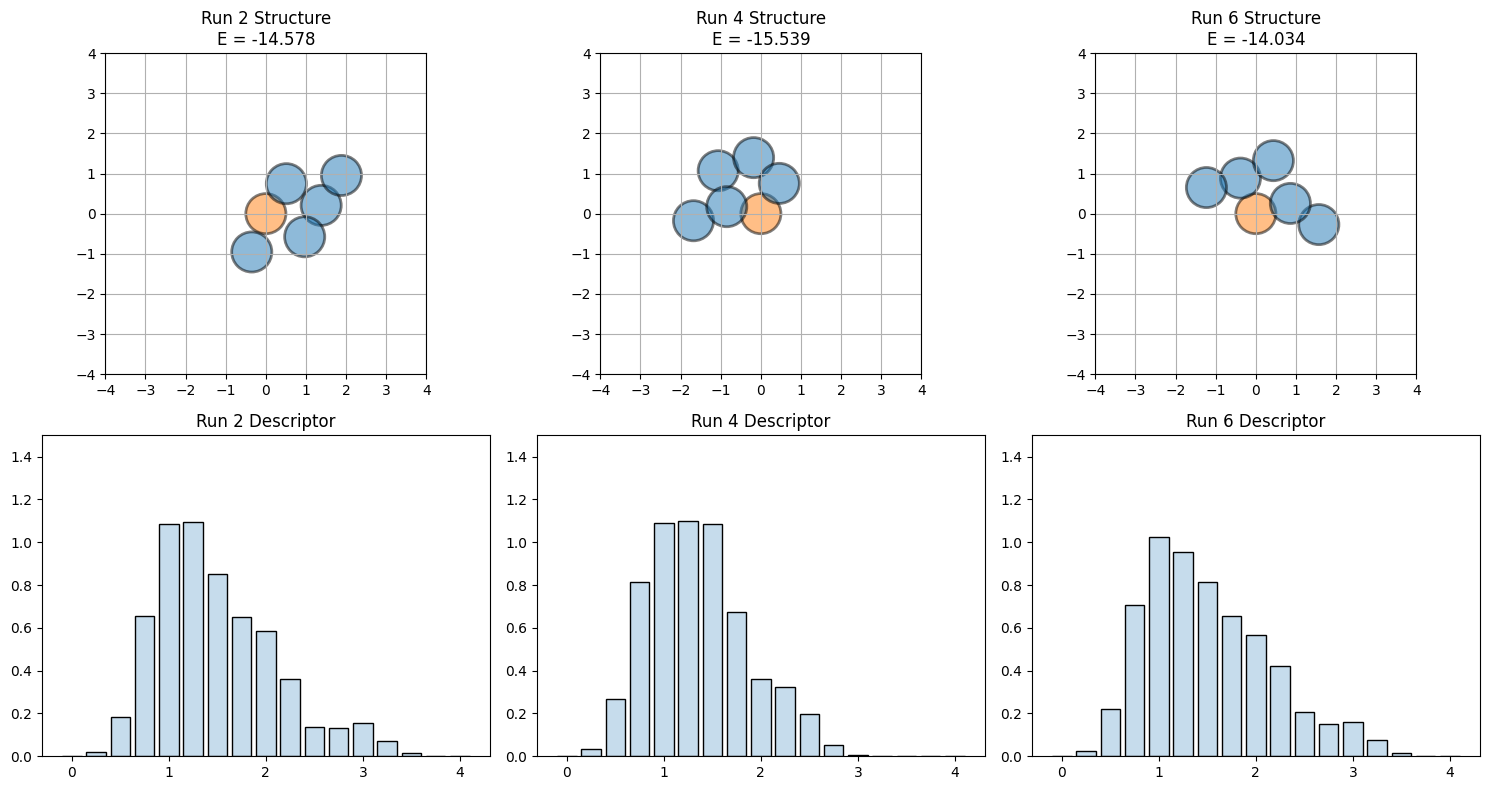

In [5]:
num_runs = 6
saved_clusters = []

# Parameters tuned to allow visiting different local minima
Nsteps = 15
kT = 1.5 
Nrattle = 3
Arattle = 0.6

for i in range(num_runs):
    # Basin hopping updates the cluster in-place and continues from the preceding structure
    acc_rate = basin_hopping(cluster, Nsteps=Nsteps, kT=kT, Nrattle=Nrattle, Arattle=Arattle)
    
    # Store a copy of the resulting cluster after every run
    saved_clusters.append(cluster.copy())
    print(f"Run {i+1}: Acceptance = {acc_rate:.2f} | Energy = {cluster.potential_energy:.3f}")

# Make a figure showing a small selection of the generated atomic structures and their descriptors
# Selecting the 2nd, 4th, and 6th structures to visualize distinct minima
selection_indices = [1, 3, 5] 

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, idx in enumerate(selection_indices):
    c = saved_clusters[idx]
    
    # Plot Structure (Top Row)
    ax_struct = axes[0, col]
    nice_plot(ax_struct)
    c.draw(ax_struct)
    ax_struct.set_title(f"Run {idx + 1} Structure\nE = {c.potential_energy:.3f}")
    
    # Plot Descriptor (Bottom Row)
    ax_desc = axes[1, col]
    c.plot_descriptor(ax_desc, add_title=False)
    ax_desc.set_title(f"Run {idx + 1} Descriptor")

plt.tight_layout()
plt.show()

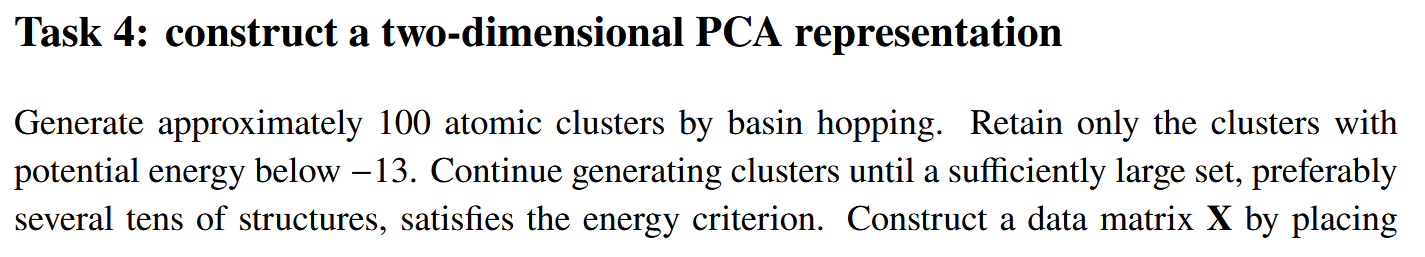
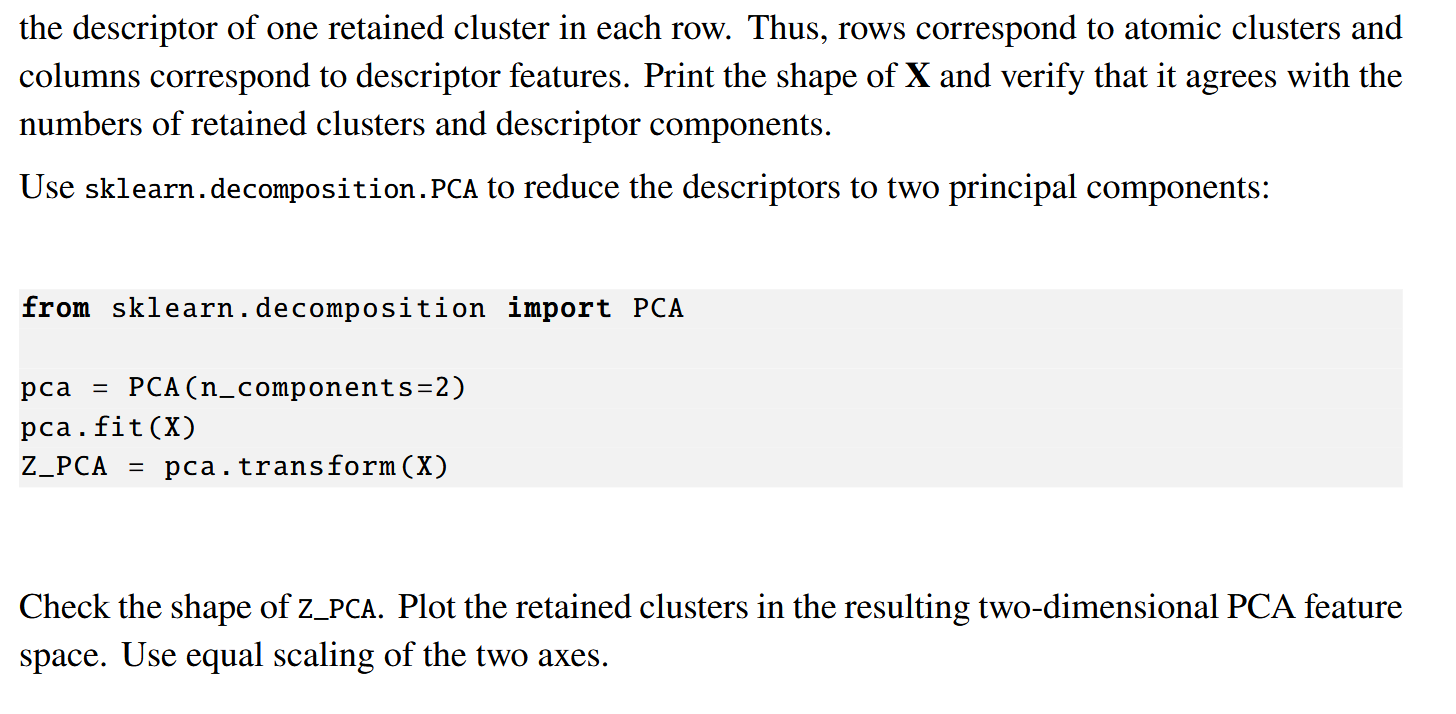

In [10]:
from sklearn.decomposition import PCA
from IPython.display import clear_output

saved_states = []
target = 30
while len(saved_states) < target: 
    acc_rate = basin_hopping(cluster, Nsteps=Nsteps, kT=kT, Nrattle=Nrattle, Arattle=Arattle)
    
    # Store a copy of the resulting cluster after every run
    if cluster.potential_energy <= -13.0:
        saved_states.append(cluster.copy())

    clear_output(wait=True)
    print(f'Number of accepted clusters: {len(saved_states)}')


Number of accepted clusters: 30


Shape of Z_PCA: (30, 2)


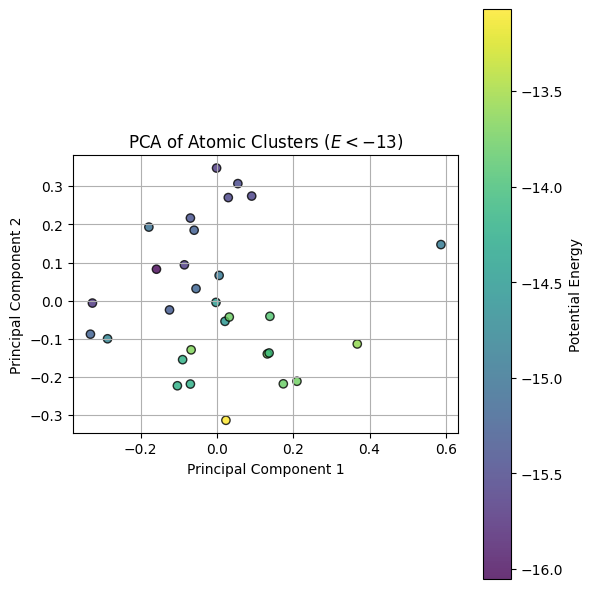

In [ ]:
X = np.array([c.descriptor for c in saved_states])

pca = PCA(n_components=2)
Z_PCA = pca.fit_transform(X)

print(f"Shape of Z_PCA: {Z_PCA.shape}")

# Plot the retained clusters in the 2D PCA feature space with equal scaling
fig, ax = plt.subplots(figsize=(6, 6))
scatter = ax.scatter(
    Z_PCA[:, 0], Z_PCA[:, 1], 
    c=[c.potential_energy for c in saved_states], 
    cmap='viridis', edgecolor='k', alpha=0.8
)

ax.set_aspect('equal')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_title('PCA of Atomic Clusters ($E < -13$)')
plt.colorbar(scatter,label='Potential Energy')
plt.grid()
plt.tight_layout()
plt.show()

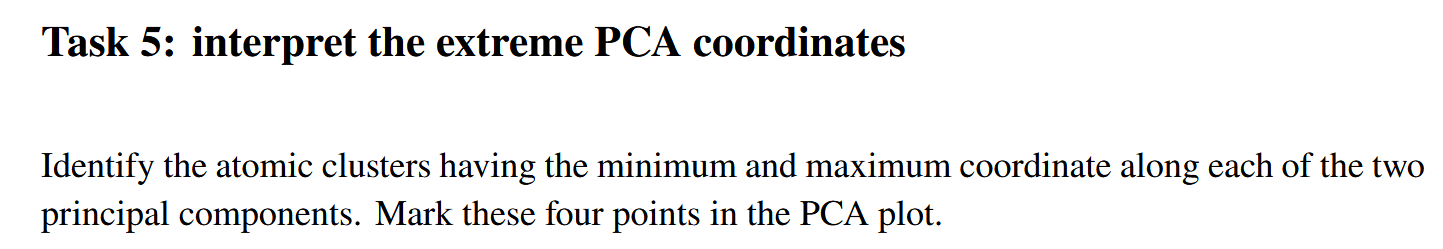
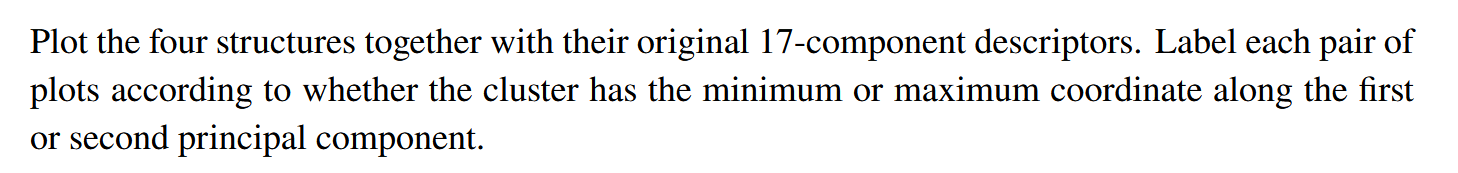
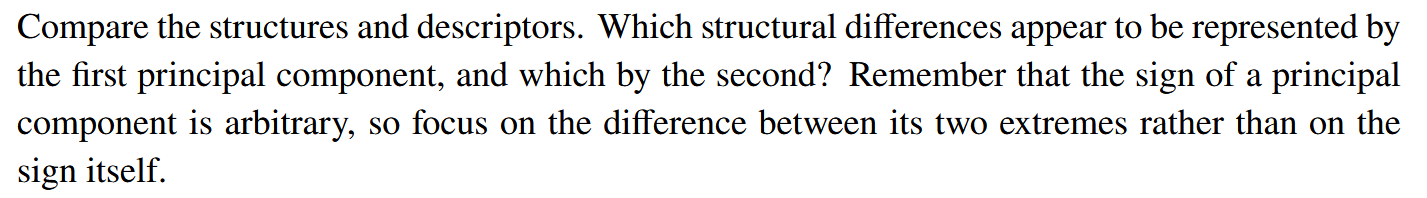

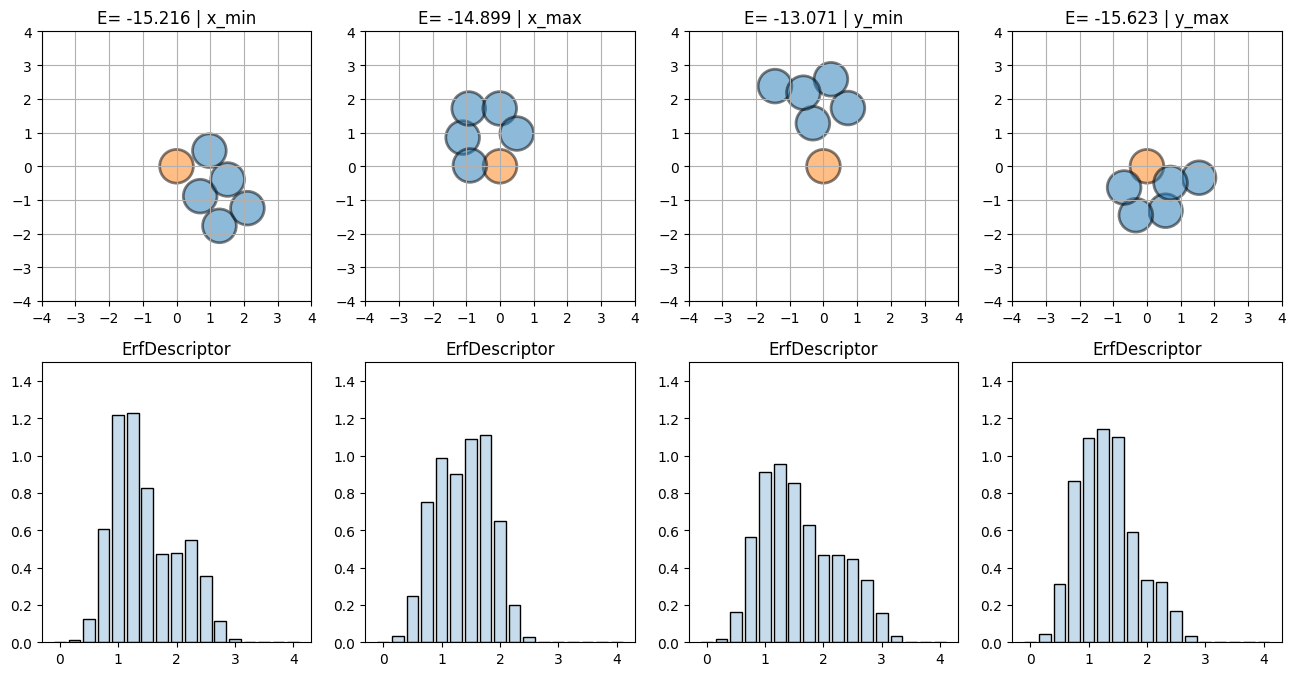

In [21]:

extremes = [np.argmin(Z_PCA[:, 0]), 
            np.argmax(Z_PCA[:, 0]), 
            np.argmin(Z_PCA[:, 1]), 
            np.argmax(Z_PCA[:, 1])]
title = ['x_min', 'x_max', 'y_min', 'y_max']

fig, ax = plt.subplots(2, 4, figsize=(16,8))

for i, idx in enumerate(extremes):
    nice_plot(ax[0, i])
    saved_states[idx].draw(ax[0, i])
    saved_states[idx].plot_descriptor(ax[1, i])
    ax[0, i].set_title(f'{ax[0, i].get_title()} | {title[i]}')

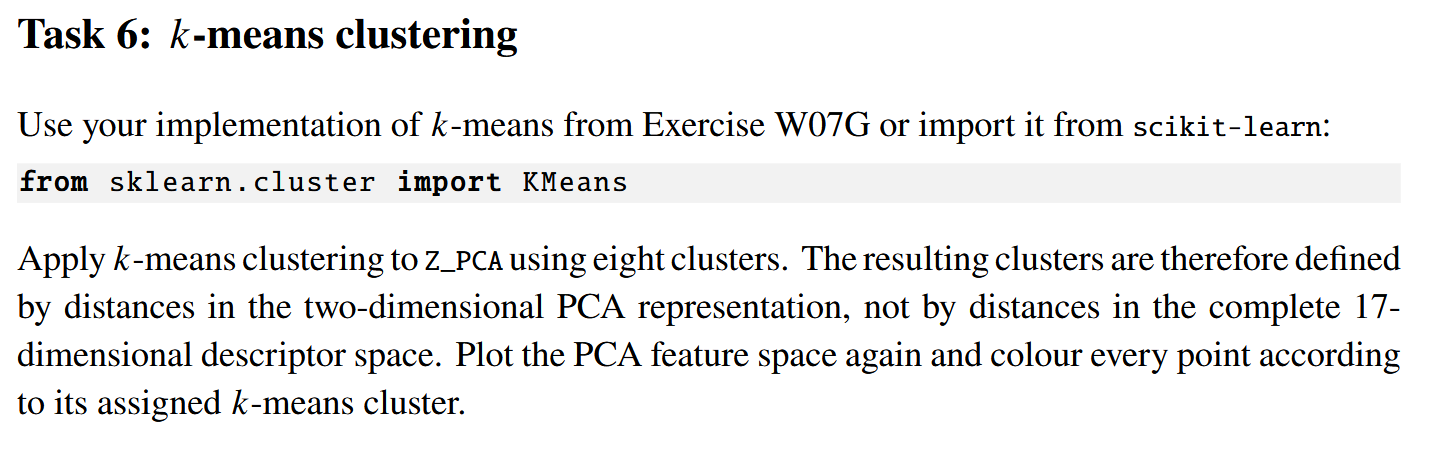

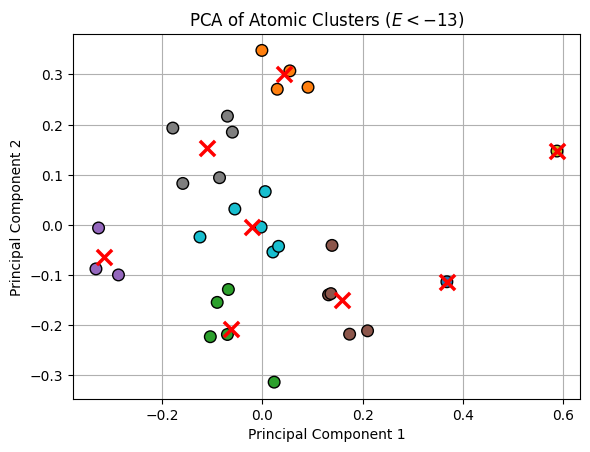

In [29]:
from sklearn.cluster import KMeans

kmeans = KMeans()
kmeans.fit(Z_PCA)
labels = kmeans.predict(Z_PCA)

fig, ax = plt.subplots(figsize=(6, 6))

# Plot points coloured by their cluster labels
ax.scatter(Z_PCA[:, 0], Z_PCA[:, 1], c=labels, cmap='tab10', s=70, edgecolor='k', zorder=2)

# Also plot the final cluster centroids as red 'X' markers
ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
           c='red', marker='x', s=120, linewidths=2.5, label='Centroids', zorder=3)

ax.set_aspect('equal')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_title('PCA of Atomic Clusters ($E < -13$)')
plt.grid()
plt.tight_layout()
plt.show()